# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [2]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 17.1MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
display(df.head())
df.info()
print(df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
(2338, 14)


In [ ]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
print(df.isnull().sum())
print('Дублікатів:', df.duplicated().sum())

Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
Дублікатів: 0


In [ ]:
# TODO: виведіть описову статистику
# Підказка: describe()
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


Висновок за первинним оглядом: датасет містить 2338 записів, 13 числових ознак типу float64 (кількості магічних інгредієнтів) і бінарну цільову змінну Cured типу int64. Пропущених значень немає, повних дублікатів теж немає, тому очищення рядків не потрібне. Мінімальне значення кожної ознаки дорівнює 1,0, що вказує на нижню межу вимірювання. Середні значення ознак лежать у межах 11-17 зі стандартними відхиленнями 7-10, тобто масштаби подібні, але для логістичної регресії та SVC стандартизація все одно бажана. Середнє значення Cured становить 0,497, тобто класи в усьому датасеті розподілені майже порівну.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
X = df.drop(columns='Cured')
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1870, 13) (468, 13)


### 5. Баланс класів на навчальній вибірці

In [ ]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
display(y_train.value_counts())
display(y_train.value_counts(normalize=True).round(4))

,count
Cured,
0,946
1,924


,proportion
Cured,
0,0.5059
1,0.4941


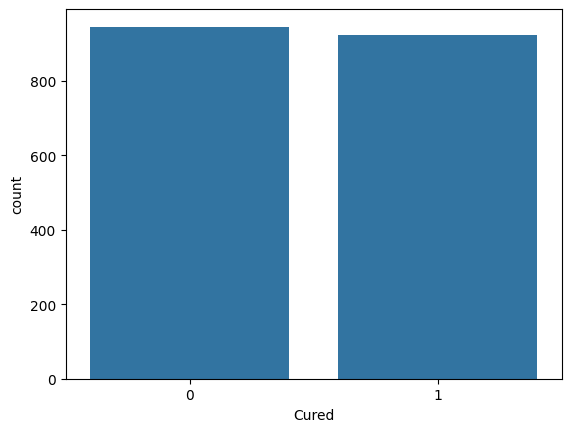

In [ ]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
sns.countplot(x=y_train)
plt.show()

Висновок: на навчальній вибірці 946 об'єктів класу 0 (50,6%) і 924 об'єкти класу 1 (49,4%), тобто класи практично збалансовані. Це означає, що Accuracy у цій задачі є інформативною метрикою: модель, яка завжди прогнозує більший клас, мала б точність лише близько 51%. Якби класи були сильно незбалансовані, висока Accuracy могла б приховувати погане розпізнавання меншого класу, і оцінку моделі довелось би робити за precision, recall та F1.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

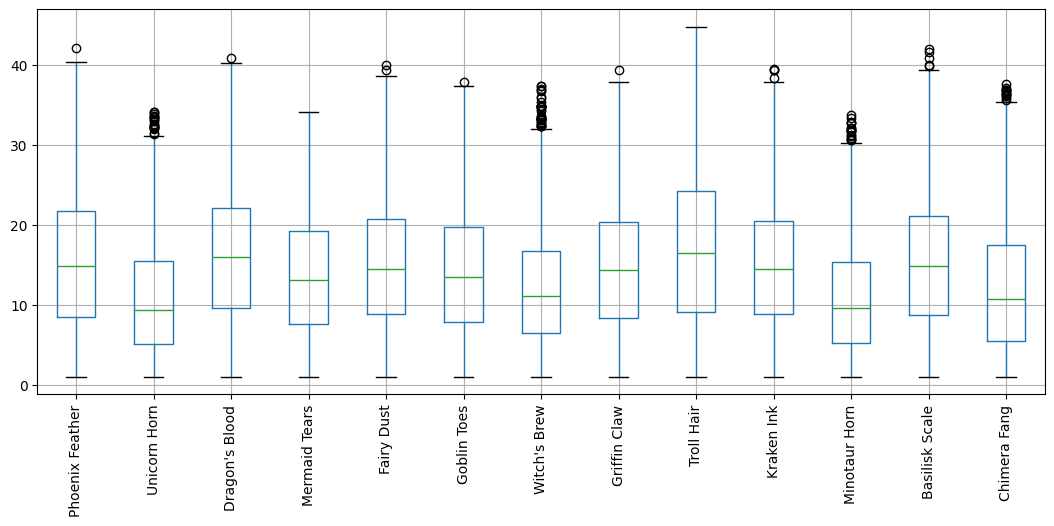

In [ ]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
X_train.boxplot(figsize=(13, 5), rot=90)
plt.show()

In [ ]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
outliers

,0
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


Висновок про викиди: за правилом 1,5 IQR на навчальній вибірці викидів небагато. Найбільше їх у Witch's Brew (33 значення, близько 1,8% вибірки), далі Unicorn Horn (20), Minotaur Horn (18) та Chimera Fang (13), в інших ознаках їх 0-5, а в Mermaid Tears і Troll Hair немає зовсім. Це, імовірно, рідкісні великі дози інгредієнтів, а не помилки вимірювання. Видаляти всі такі рядки без перевірки не варто: ми втратимо частину й без того невеликої вибірки (1870 рядків), а екстремальні кількості інгредієнтів можуть бути саме тими, що впливають на результат лікування. Крім того, очищення лише навчальної вибірки зсуває її розподіл відносно тестової.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

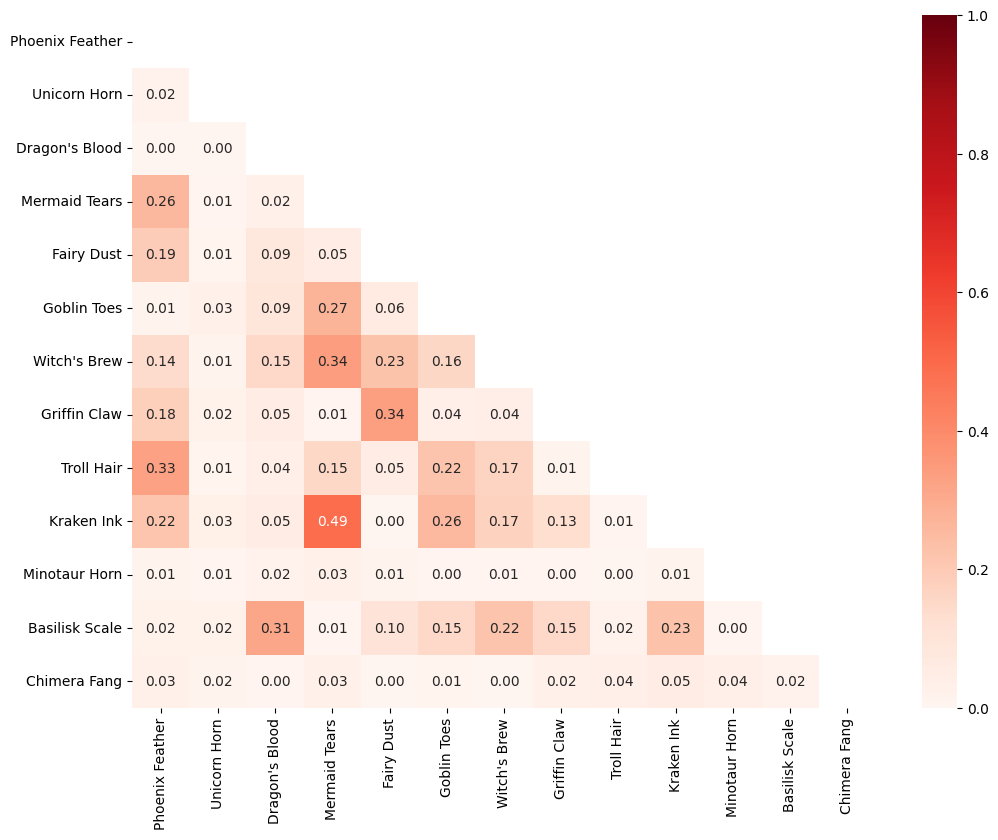

,,0
Kraken Ink,Mermaid Tears,0.490744
Witch's Brew,Mermaid Tears,0.343493
Griffin Claw,Fairy Dust,0.339391
Troll Hair,Phoenix Feather,0.330043
Basilisk Scale,Dragon's Blood,0.313266


In [ ]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.show()
mtx.where(~mask).stack().sort_values(ascending=False).head(5)

In [ ]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
corr_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured')
corr_target.sort_values(key=abs, ascending=False)

,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


Висновок про кореляції: ознаки між собою корелюють слабко. Найбільша кореляція у пари Kraken Ink і Mermaid Tears (0,49), далі Witch's Brew і Mermaid Tears (0,34), Griffin Claw і Fairy Dust (0,34), Troll Hair і Phoenix Feather (0,33), Basilisk Scale і Dragon's Blood (0,31). Тому мультиколінеарності немає і видаляти ознаки не потрібно. Зі змінною Cured найсильніше пов'язані Troll Hair (0,49) та Witch's Brew (0,25), а для решти ознак кореляція за модулем не перевищує 0,06, тобто лінійного зв'язку майже немає. Слабка лінійна кореляція не означає відсутності зв'язку: він може бути нелінійним або виникати від поєднання кількох інгредієнтів.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

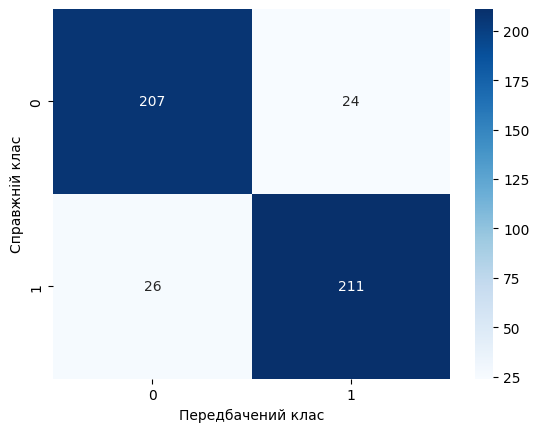

In [ ]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()

In [ ]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results = pd.DataFrame({'Справжній клас': y_test, 'Передбачений клас': y_pred})
results.sample(10, random_state=42)

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


Висновок щодо якості логістичної регресії: Accuracy на тестовій вибірці становить 0,893. Помилок небагато (50 із 468 прогнозів), і вони розподілені майже порівну між двома класами: precision і recall для обох класів становлять близько 0,89-0,90, тому модель не зсунута в бік жодного класу. У прикладі з 10 випадкових спостережень правильно передбачено 8, одна помилка полягає в хибному прогнозі одужання (справжній клас 0, передбачено 1), а інша в пропущеному одужанні (справжній клас 1, передбачено 0). Однієї метрики Accuracy недостатньо, бо вона не показує, яких саме помилок більше, а ціна помилок різна: хибний прогноз одужання, імовірно, небезпечніший за хибний прогноз неодужання. Тому потрібно дивитись також на матрицю помилок, precision, recall і F1.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 500, 1000],
}
param_dist = {
    'C': np.logspace(-3, 3, 50),
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 200, 500, 1000, 2000],
}

In [ ]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid_search = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print(grid_search.best_params_)
print(round(grid_search.best_score_, 4))

{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
0.8674


In [ ]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=20, cv=3, scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)
print(random_search.best_params_)
print(round(random_search.best_score_, 4))

{'solver': 'saga', 'max_iter': 1000, 'C': np.float64(10.985411419875572)}
0.8674


In [ ]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
else:
    best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
print(best_model.get_params()['C'], best_model.get_params()['solver'], best_model.get_params()['max_iter'])
print('Accuracy:', round(accuracy_score(y_test, y_pred_best), 4))
print(classification_report(y_test, y_pred_best))

10 lbfgs 100
Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



Висновок про підбір параметрів: GridSearchCV обрав C = 10, solver = lbfgs і max_iter = 100, а RandomizedSearchCV обрав solver = saga, max_iter = 1000 і C близько 11. Обидва методи дали однакову середню Accuracy на кросвалідації 0,8674, тобто знайшли практично рівноцінні налаштування зі слабкішою регуляризацією, ніж за замовчуванням (C = 1). Для оцінки на тесті використано модель із GridSearchCV (за рівності результатів обирається вона). Accuracy на тесті 0,8932 і метрики класифікаційного звіту не змінились порівняно з базовою моделлю, тобто підбір гіперпараметрів не покращив якість. Це очікувано: логістична регресія лінійна, і її обмеження пов'язане з формою моделі, а не з параметрами регуляризації.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
models = {
    'Logistic Regression': best_model,
    'SVC': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
}
scores = {}
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    scores[name] = {'Accuracy': accuracy_score(y_test, pred), 'F1-score': f1_score(y_test, pred)}
comparison = pd.DataFrame(scores).T.sort_values('F1-score', ascending=False).round(4)
display(comparison)
print('Найкраща модель:', comparison.index[0])

,Accuracy,F1-score
SVC,0.9594,0.9600
Logistic Regression,0.8932,0.8941
Decision Tree,0.8654,0.8657


Найкраща модель: SVC


Порівняння трьох моделей: найкращою є SVC з Accuracy 0,959 та F1-score 0,960, далі йдуть логістична регресія (0,893 і 0,894) та дерево рішень (0,865 і 0,866). Вибір зроблено за F1-score на однаковій тестовій вибірці, а за Accuracy порядок моделей той самий, до того ж класи збалансовані. Перевага SVC над логістичною регресією на 6-7 відсоткових пунктів свідчить, що залежність між інгредієнтами та результатом лікування нелінійна: ядро RBF дозволяє будувати криву межу рішення, а логістична регресія розділяє класи лише гіперплощиною. Дерево рішень без обмеження глибини, імовірно, перенавчилось на навчальній вибірці і гірше узагальнюється. Слід враховувати, що SVC і дерево навчались із параметрами за замовчуванням без підбору, а тестова вибірка містить лише 468 об'єктів, тому значення метрик мають певну похибку.

### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

Висновки до лабораторної роботи.

Первинний аналіз показав, що датасет містить 2338 записів із 13 числовими ознаками та бінарною ціллю, без пропусків і дублікатів. Класи збалансовані (50,6% і 49,4% у навчальній вибірці), а мінімальне значення кожної ознаки дорівнює 1,0.

На навчальній вибірці викидів за правилом 1,5 IQR небагато (найбільше у Witch's Brew, 33 значення), тому їх не видаляли. Ознаки між собою корелюють слабко (максимум 0,49 для Kraken Ink і Mermaid Tears), а з цільовою змінною найсильніше пов'язані Troll Hair (0,49) і Witch's Brew (0,25).

Базова логістична регресія після стандартизації досягла Accuracy 0,893 на тестовій вибірці, а precision, recall та F1 для обох класів становлять близько 0,89-0,90, помилки розподілені порівну.

Підбір гіперпараметрів за допомогою GridSearchCV і RandomizedSearchCV (cv=3) дав однакову Accuracy на кросвалідації 0,8674 для обох методів, але метрики на тесті не змінились, тому покращення не було.

Найкращою з трьох моделей виявилась SVC (Accuracy 0,959, F1-score 0,960), далі логістична регресія (0,893 і 0,894) та дерево рішень (0,865 і 0,866). Перевага SVC пояснюється, імовірно, нелінійною залежністю між інгредієнтами та результатом лікування, яку лінійна модель відтворити не може.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.